# Comoving cosmology: spherical top-hat collapse

A uniform, cold, overdense sphere in an Einstein-de Sitter universe evolves exactly like a closed
FRW universe (Peebles 1980, sec. 19; Gunn & Gott 1972): its radius follows R = A (1 - cos theta),
t = B (theta - sin theta), and it turns around at 1 + delta = 9 pi² / 16. Here: comoving radius
0.15 in a periodic unit box, starting at z = 50 (a = 1/51) with the growing-mode velocity, turning
around at a = 0.5, pressureless (p only at a floor of 1e-10). The box outside the sphere is lowered
so that the mean density is exactly 1: by Gauss the interior then feels exactly the sphere's
overdensity despite the mean-subtracted Poisson solve.

The run is LUNA's comoving integration (super-comoving variables, gravity from the periodic
multigrid solve, `CosmologicalIntegration=True`) at 64³, FP64, HLLC, minmod: the setup of
`tests/test_cosmo_tophat_collapse.py` (exact solution: `luna.cosmology.exact_tophat`, checked against a
direct integration of R'' = -G M / R²). Compared: the mean density of the inner half of the sphere
and the slope of the interior velocity v~ = s r against the exact solution, at a = 0.1, 0.25, 0.5.

Runtime: about 2 minutes on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

**A custom initial state through the run path.** LUNA's registered problems (`test_problem`) fix
their initial states. A state of our own goes to `launch(cfg, U0=U)`: `U` holds the conserved
variables on the whole grid in the run's own dimension, `(3, Nx)` in 1D (rho, rho vx, E),
`(4, Nx, Ny)` in 2D, `(5, Nx, Ny, Nz)` in 3D, energy last; a shape that does not fit the config is
refused. It takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`), sharded like a
registered problem; `test_problem` then only names the run.

In [2]:
import glob
from scipy.optimize import brentq
from luna.file_io.read_snapshot import read_snapshot
from luna.ic_generation import zeldovich
from luna.cosmology.exact_tophat import TopHat

A_I, R0, A_TA, P0, N = 1.0 / 51.0, 0.15, 0.5, 1e-10, 64
A_SNAP = (0.1, 0.25)
th = TopHat(brentq(lambda d: TopHat(d, A_I).a_turnaround() - A_TA, 1e-3, 0.2), A_I)
delta_i = th.one_plus_delta([A_I])[0] - 1.0
print(f"initial overdensity delta_i = {delta_i:.5f}; 1 + delta at turnaround = {th.one_plus_delta([A_TA])[0]:.4f} "
      f"(9 pi²/16 = {9 * np.pi ** 2 / 16:.4f})")

x = (np.arange(N) + 0.5) / N - 0.5
X = np.stack(np.meshgrid(x, x, x, indexing="ij"))
r = np.sqrt((X ** 2).sum(0))


def initial():
    """rho~ = 1 + delta_i inside R0, lowered outside to mean 1; v~ the growing mode scaled to the exact interior."""
    inside = r < R0
    rho = np.where(inside, 1.0 + delta_i, 1.0 - delta_i * inside.mean() / (1.0 - inside.mean()))
    k = 2 * np.pi * np.fft.fftfreq(N, 1.0 / N)
    KK = np.stack(np.meshgrid(k, k, k, indexing="ij"))
    k2 = (KK ** 2).sum(0)
    k2[0, 0, 0] = 1.0
    dk = np.fft.fftn(rho - 1.0)
    s = 3.0 * A_I ** 2 * th.vpec_over_r([A_I])[0] / delta_i          # grad lap^-1 delta = delta x / 3 inside
    v = np.stack([np.real(np.fft.ifftn(-1j * KK[i] * dk / k2)) for i in range(3)]) * s
    U = np.zeros((5, N, N, N))
    U[0], U[1:4] = rho, rho * v
    U[-1] = 1.5 * P0 + 0.5 * rho * (v ** 2).sum(0)
    return U


def core(a):
    """The inner half of the sphere's comoving radius at a."""
    return r < 0.5 * R0 * (th.one_plus_delta([a])[0] / th.one_plus_delta([A_I])[0]) ** (-1.0 / 3.0)

initial overdensity delta_i = 0.04311; 1 + delta at turnaround = 5.5517 (9 pi²/16 = 5.5517)


In [3]:
cfg = replace(BASE, test_problem="Zeldovich-Pancake", SPATIAL_DIMENSION=3, Nx=N, Ny=N, Nz=N,
              Lx=1.0, Ly=1.0, Lz=1.0, BOUNDARY=0, gamma=5.0 / 3.0, CosmologicalIntegration=True,
              cosmo_Omega_m=1.0, cosmo_Omega_L=0.0, cosmo_H0=1.0, a_init=A_I, a_end=A_TA,
              cosmo_p_floor=P0, cosmo_T_floor=0.0, problem=zeldovich.Params(),
              gravity_precision="double", gravity_proper_mixed=False,
              cosmo_snapshot_a=A_SNAP, output_dir="snapshots/nb10/run")
res, wall = run(cfg, U0=initial())
print(f"{res.n_steps} steps to a = {A_TA}, {wall:.0f} s")
U = np.asarray(res.extra["U"], np.float64)

325 steps to a = 0.5, 49 s


In [4]:
# the test's bounds at 64³ (1.3 x its measurement on a GPU): core 1.1e-3, 5.8e-3, 0.11; slope 5.1e-3, 9.3e-3, 0.09
snaps = sorted(glob.glob(f"{cfg.output_dir}/snapdir_*"))      # at a = 0.1, 0.25 and the end
assert len(snaps) == len(A_SNAP) + 1, snaps
rows = []
for a, d in zip(A_SNAP, snaps):
    rows.append((a, read_snapshot(d)["rho"][core(a)].mean(), None))
c = core(A_TA)
vx = U[1][c] / U[0][c]
slope = (vx * X[0][c]).sum() / (X[0][c] ** 2).sum()
rows.append((A_TA, U[0][c].mean(), slope / (A_TA ** 2 * th.vpec_over_r([A_TA])[0]) - 1))
for a, rho_c, ds in rows:
    ex = th.one_plus_delta([a])[0]
    print(f"a = {a:5.3f}: core rho~ = {rho_c:.4f}, exact {ex:.4f}, error {rho_c / ex - 1:+.2e}"
          + (f"; v~ slope error {ds:+.2e}" if ds is not None else ""))

a = 0.100: core rho~ = 1.2569, exact 1.2558, error +8.37e-04
a = 0.250: core rho~ = 1.9113, exact 1.9029, error +4.41e-03
a = 0.500: core rho~ = 5.9882, exact 5.5517, error +7.86e-02; v~ slope error +6.81e-02


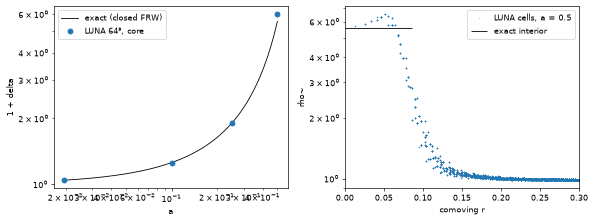

In [5]:
aa = np.geomspace(A_I, A_TA, 200)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), dpi=60)
ax[0].loglog(aa, th.one_plus_delta(aa), "k-", lw=1, label="exact (closed FRW)")
ax[0].loglog([A_I] + [a for a, *_ in rows], [1 + delta_i] + [rc for _, rc, _ in rows], "o", label="LUNA 64³, core")
ax[0].set_xlabel("a"); ax[0].set_ylabel("1 + delta"); ax[0].legend()
ax[1].plot(r.ravel(), U[0].ravel(), ".", ms=1, alpha=0.3, label="LUNA cells, a = 0.5")
R_ta = R0 * (th.one_plus_delta([A_TA])[0] / th.one_plus_delta([A_I])[0]) ** (-1.0 / 3.0)
ax[1].hlines(th.one_plus_delta([A_TA])[0], 0, R_ta, color="k", lw=1, label="exact interior")
ax[1].set_xlim(0, 0.3); ax[1].set_yscale("log"); ax[1].set_xlabel("comoving r"); ax[1].set_ylabel("rho~")
ax[1].legend()
fig.tight_layout()

**What this shows.** The core density follows the exact solution to 8.4e-4 at a = 0.1 and 4.4e-3 at a = 0.25; at turnaround it is 7.9 % high and the velocity slope 6.8 % off, where the sphere has shrunk to a radius of 5.5 cells (the core: 2.7 cells). All are inside the test's 64³ bounds (1.1e-3, 5.8e-3, 0.11; slope 0.09); the test's 128³ and 256³ runs on a GPU bring the turnaround error down to 3.8e-3 and 5.8e-4.

Status (docs/CLAIMS.md): *validated*, "Spherical top-hat collapse against the exact closed-FRW
solution", `tests/test_cosmo_tophat_collapse.py:141` (also the Layzer-Irvine energy budget). The
Zel'dovich pancake (`test_problem="Zeldovich-Pancake"`, exact solution
`luna.ic_generation.zeldovich.exact`) is *shown* (regression only).